In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import re
import nltk

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [ ]:
import pandas as pd
import os
import kagglehub

path = kagglehub.dataset_download(
    "waalbannyantudre/hate-speech-detection-curated-dataset"
)

print("Path:", path)

# File name check
print(os.listdir(path))

Using Colab cache for faster access to the 'hate-speech-detection-curated-dataset' dataset.
Path: /kaggle/input/hate-speech-detection-curated-dataset
['HateSpeechDatasetBalanced.csv', 'HateSpeechDataset.csv']


In [ ]:
df = pd.read_csv(os.path.join(path, "HateSpeechDatasetBalanced.csv"))

In [ ]:
print(df.shape)

print(df.head())

print(df.info())

print(df.describe())

(726119, 2)
                                             Content  Label
0  denial of normal the con be asked to comment o...      1
1  just by being able to tweet this insufferable ...      1
2  that is retarded you too cute to be single tha...      1
3  thought of a real badass mongol style declarat...      1
4                                afro american basho      1
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 726119 entries, 0 to 726118
Data columns (total 2 columns):
 #   Column   Non-Null Count   Dtype 
---  ------   --------------   ----- 
 0   Content  726119 non-null  object
 1   Label    726119 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 11.1+ MB
None
               Label
count  726119.000000
mean        0.502018
std         0.499996
min         0.000000
25%         0.000000
50%         1.000000
75%         1.000000
max         1.000000


In [ ]:
print(df.isnull().sum())

Content    0
Label      0
dtype: int64


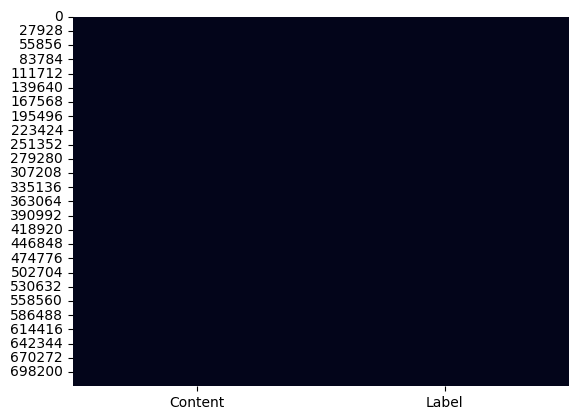

In [ ]:
sns.heatmap(df.isnull(), cbar=False)

plt.show()

In [ ]:
print("Duplicates :", df.duplicated().sum())

Duplicates : 25046


In [ ]:
df.drop_duplicates(inplace=True)

df.reset_index(drop=True, inplace=True)

In [ ]:
print(df["Label"].value_counts())

Label
1    359097
0    341976
Name: count, dtype: int64


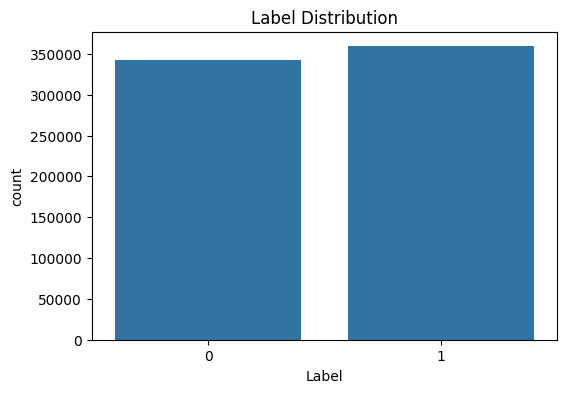

In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(data=df, x="Label")

plt.title("Label Distribution")

plt.show()

In [ ]:
nltk.download("stopwords")
nltk.download("punkt")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [ ]:
stop_words = set(stopwords.words("english"))

def clean_text(text):

    text = str(text).lower()

    text = re.sub(r"http\\S+", "", text)

    text = re.sub(r"www\\S+", "", text)

    text = re.sub(r"[^a-zA-Z ]", "", text)

    words = text.split()

    words = [
        word for word in words
        if word not in stop_words
    ]

    return " ".join(words)

In [ ]:
df["processed_text"] = df["Content"].apply(clean_text)

print(df["processed_text"].head())

0    denial normal con asked comment tragedies emot...
1    able tweet insufferable bullshit proves trump ...
2                            retarded cute single life
3    thought real badass mongol style declaration w...
4                                  afro american basho
Name: processed_text, dtype: object


In [ ]:
df["text_length"] = df["processed_text"].apply(len)

print(df["text_length"].describe())

count    701073.000000
mean        129.133323
std         166.150875
min           0.000000
25%          39.000000
50%          72.000000
75%         148.000000
max        9988.000000
Name: text_length, dtype: float64


In [ ]:
df["text_length"] = df["processed_text"].apply(len)

print(df["text_length"].describe())

count    701073.000000
mean        129.133323
std         166.150875
min           0.000000
25%          39.000000
50%          72.000000
75%         148.000000
max        9988.000000
Name: text_length, dtype: float64


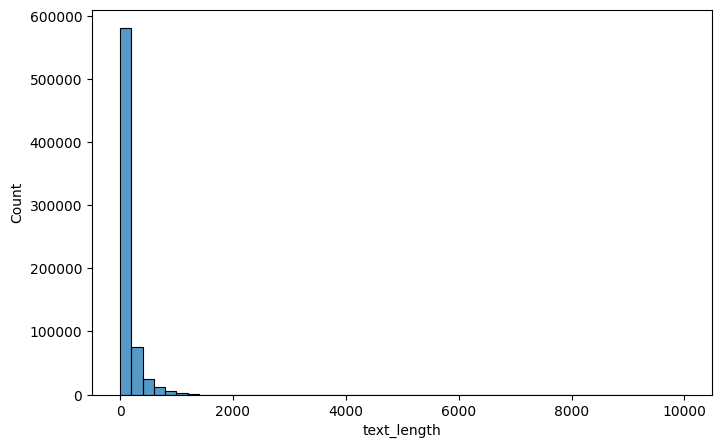

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(
    df["text_length"],
    bins=50
)

plt.show()

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1,2),
    min_df=2
)

X = tfidf.fit_transform(df["processed_text"])
y = df["Label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = LogisticRegression(
    max_iter=2000,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Train:", model.score(X_train, y_train))
print("Test :", model.score(X_test, y_test))

Train: 0.8356143622806486
Test : 0.8270441821488429


In [ ]:
import joblib

joblib.dump(model, "hate_speech_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Model and Vectorizer Saved Successfully")

Model and Vectorizer Saved Successfully


In [ ]:
import joblib

model = joblib.load("hate_speech_model.pkl")
tfidf = joblib.load("tfidf_vectorizer.pkl")

print("Model Loaded Successfully")

Model Loaded Successfully


In [ ]:
text = input("Enter Text: ")

text_clean = clean_text(text)

text_tfidf = tfidf.transform([text_clean])

pred = model.predict(text_tfidf)[0]

if pred == 1:
    print("⚠️ Hate Speech Detected")
else:
    print("✅ Not Hate Speech")

Enter Text: Have a nice day
✅ Not Hate Speech
